## Importando as bibliotecas

In [52]:
import pandas as pd
import numpy as np
from scipy import stats as st 


## Carregue os dados

In [53]:
# Carregando os arquivos de dados em diferentes DataFrames
calls_df = pd.read_csv('data/megaline_calls.csv')
internet_df = pd.read_csv('data/megaline_internet.csv')
messages_df = pd.read_csv('data/megaline_messages.csv')
plans_df = pd.read_csv('data/megaline_plans.csv')
users_df = pd.read_csv('data/megaline_users.csv')

### Preparação dos dados

### Planos

In [54]:
# Imprimindo informações gerais/resumo sobre o DataFrame dos planos
plans_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 272.0 bytes


In [55]:
# Imprimindo uma amostra de dados dos planos
plans_df.head()


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate




Após a verificação, eu notei que não temos a existência de valores ausentes, os tipos de dados me parecem coerentes com o tipos que variaveis que eles são, porém, na coluna plan_name,  ela esta como objet, mas podemos converter ela para category e também temos valores muitos altos.

## Corrijindo os dados

In [56]:
plans_df['gb_per_month_included'] = plans_df['mb_per_month_included'] / 1024
plans_df['plan_name'] = plans_df['plan_name'].astype('category')

## Enriquecendo os dados

In [57]:
plans_df['cost_per_gb_included'] = plans_df['usd_monthly_pay'] / plans_df['gb_per_month_included']

## Usuários

In [58]:
# Imprimindo informações gerais/resumo sobre o DataFrame dos usuários
users_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 62.1 KB


In [59]:
# Amostra de dados dos usuários
users_df.sample(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
86,1086,Adena,Macias,36,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-01-13,ultimate,NaN
279,1279,Neal,Duke,27,"Baton Rouge, LA MSA",2018-02-05,ultimate,NaN
156,1156,Anette,Chambers,71,"Albuquerque, NM MSA",2018-03-25,surf,NaN
400,1400,Kenton,Hickman,72,"Riverside-San Bernardino-Ontario, CA MSA",2018-03-08,surf,NaN
132,1132,Edward,Roberts,39,"San Francisco-Oakland-Berkeley, CA MSA",2018-04-14,ultimate,NaN


Após a verificação do dataset, de uma forma geral esta coerente, os tipos de colunas estão organizados da forma correto, porém temos muitos valores faltantes na coluna churn_date.

### Corrija os dados

In [60]:
users_df['churn_date'] = pd.to_datetime(users_df['churn_date'])

### Enriqueça os dados

In [61]:
users_df['reg_date'] = pd.to_datetime(users_df['reg_date'])
users_df['churn_date'] = pd.to_datetime(users_df['churn_date'])

users_df['is_activate'] = users_df['churn_date'].isna()

users_df['days_with_company'] = (
    users_df['churn_date'] - users_df['reg_date']
).dt.days

## Chamadas

In [62]:
# Imprimindo informações gerais/resumo sobre o DataFrame das chamadas
calls_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 6.5 MB


In [63]:
# Imprimindo uma amostra de dados das chamadas
calls_df.sample(5)


,id,user_id,call_date,duration
118271,1412_555,1412,2018-12-11,7.44
57238,1203_629,1203,2018-04-08,18.47
98416,1353_123,1353,2018-09-15,0.00
41096,1151_274,1151,2018-12-26,1.47
64268,1232_591,1232,2018-09-30,9.20


De modo geral o dataset esta bem organizado, sem valores ausentes, mas com algumas divergencias nos tipos de dados das colunas. Na coluna call_date esta como object, mas por se tratar de uma data é preciso converter para o tipo datetime.  

### Corrija os dados

In [64]:
calls_df['call_date'] = pd.to_datetime(calls_df['call_date'])

### Enriqueça os dados

In [65]:
calls_df['month'] = calls_df['call_date'].dt.month
calls_df['weekday'] = calls_df['call_date'].dt.day
calls_df['total_duration_user'] = calls_df.groupby('user_id')['duration'].sum()

## Mensagens

In [66]:
# Informações gerais/resumo sobre o DataFrame das mensagens
messages_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 3.0 MB


In [67]:
# Imprimindo uma amostra dos dados das mensagens
messages_df.sample(5)


,id,user_id,message_date
25121,1148_158,1148,2018-12-18
12447,1081_202,1081,2018-11-27
72150,1467_482,1467,2018-08-20
705,1007_7,1007,2018-10-17
29793,1183_188,1183,2018-11-01


O dataset está coerente, não temos valores ausentes, os tipos de dados estão corretos, porém na coluna message_date, está como object, mas por se tratar de uma data, é precio converter para datetime.

### Corrija os dados

In [68]:
messages_df['message_date'] = pd.to_datetime(messages_df['message_date'])

### Enriqueça os dados

In [69]:
messages_df['messages_per_user'] = messages_df.groupby('user_id').size()

## Internet

In [70]:
# Imprimindo informações gerais/resumo sobre o DataFrame da internet
internet_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 5.0 MB


In [71]:
#  Imprimindo uma amostra de dados para o tráfego da internet
internet_df.sample(5)


,id,user_id,session_date,mb_used
64007,1293_562,1293,2018-10-28,556.86
58532,1263_336,1263,2018-03-15,426.19
67491,1313_165,1313,2018-12-09,230.37
37781,1171_152,1171,2018-12-14,200.90
37073,1166_239,1166,2018-12-16,587.97


Ao analisar o dataset, pode-se obsevar que de uma forma geral, ele está bem coerente, porém a coluna session_date está com o tipo de dado object, mas por se tratar de uma data, é necessario mudar para o tipo de dado datetime.

### Corrija os dados

In [72]:
internet_df['session_date'] = pd.to_datetime(internet_df['session_date']) 

### Enriqueça os dados

In [73]:
internet_df['gb_used'] = internet_df['mb_used'] / 1024

internet_df['internet_per_user'] = internet_df.groupby('mb_used')['user_id'].sum()



## Condições dos planos

In [74]:
# Imprimindo as condições dos planos 
plans_df.head()


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included,cost_per_gb_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0,1.333333
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0,2.333333


In [75]:
# Número de chamadas feitas por cada usuário por mês. 
calls_df['call_date'] = pd.to_datetime(calls_df['call_date'])


calls_df['month'] = calls_df['call_date'].dt.month

calls_per_month = calls_df.groupby(['user_id', 'month']).size().reset_index(name='calls_count')

calls_per_month

,user_id,month,calls_count
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64
...,...,...,...
2253,1498,12,39
2254,1499,9,41
2255,1499,10,53
2256,1499,11,45


In [76]:
# Quantidade de minutos gastos por cada usuário por mês.
calls_df['month'] = calls_df['call_date'].dt.month

calls_per_minutes = calls_df.groupby(['user_id', 'month'])['duration'].sum().reset_index(name='total_per_month_minutes')
calls_per_minutes

,user_id,month,total_per_month_minutes
0,1000,12,116.83
1,1001,8,171.14
2,1001,9,297.69
3,1001,10,374.11
4,1001,11,404.59
...,...,...,...
2253,1498,12,324.77
2254,1499,9,330.37
2255,1499,10,363.28
2256,1499,11,288.56


In [77]:
# Número de mensagens enviadas por cada usuário por mês.
messages_df['message_date'] = pd.to_datetime(messages_df['message_date'])

messages_df['month'] = messages_df['message_date'].dt.month

messages_per_month = messages_df.groupby(['user_id', 'month']).size().reset_index(name='messages_count')
messages_per_month

,user_id,month,messages_count
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36
...,...,...,...
1801,1496,9,21
1802,1496,10,18
1803,1496,11,13
1804,1496,12,11


In [78]:
# Volume de tráfego de internet usado por cada usuário por mês. 
internet_df['session_date'] = pd.to_datetime(internet_df['session_date'])
internet_df['month'] = internet_df['session_date'].dt.month

internet_per_user = internet_df.groupby(['user_id', 'month'])['mb_used'].sum().reset_index(name='count_internet')
internet_per_user


,user_id,month,count_internet
0,1000,12,1901.47
1,1001,8,6919.15
2,1001,9,13314.82
3,1001,10,22330.49
4,1001,11,18504.30
...,...,...,...
2272,1498,12,23137.69
2273,1499,9,12984.76
2274,1499,10,19492.43
2275,1499,11,16813.83


In [79]:
# Juntando os dados de chamadas, minutos, mensagens e internet com base em user_id e month

merged_df = (
    calls_per_month
    .merge(
        calls_per_minutes,
        on=['user_id', 'month'],
        how='outer'
    )
    .merge(
        messages_per_month,
        on=['user_id', 'month'],
        how='outer'
    )
    .merge(
        internet_per_user,
        on=['user_id', 'month'],
        how='outer'
    )
)



In [80]:
# Adicionando as informações sobre o plano

merged_df = merged_df.merge(users_df, on=['user_id'], how='left')
merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]
print(merged_df)
merged_df = merged_df.merge(plans_df, left_on='plan', right_on='plan_name',how='left')


      user_id  month  calls_count  total_per_month_minutes  messages_count  \
0        1000     12         16.0                   116.83            11.0   
1        1001      8         27.0                   171.14            30.0   
2        1001      9         49.0                   297.69            44.0   
3        1001     10         65.0                   374.11            53.0   
4        1001     11         64.0                   404.59            36.0   
...       ...    ...          ...                      ...             ...   
2288     1498     12         39.0                   324.77             NaN   
2289     1499      9         41.0                   330.37             NaN   
2290     1499     10         53.0                   363.28             NaN   
2291     1499     11         45.0                   288.56             NaN   
2292     1499     12         65.0                   468.10             NaN   

      count_internet first_name   last_name  age  \
0          

In [81]:
# Receita mensal para cada usuário

num_cols = merged_df.select_dtypes(include='number').columns
merged_df[num_cols] = merged_df[num_cols].fillna(0)

# Calcular o consumo de internet em GB
merged_df['gb_used'] = merged_df['count_internet'] / 1024

# Calcular os valores excedentes, sem permitir valores negativos
merged_df['extra_minutes'] = (merged_df['total_per_month_minutes'] - merged_df['minutes_included']).clip(lower=0)

merged_df['extra_messages'] = (merged_df['messages_count'] - merged_df['messages_included']).clip(lower=0)

merged_df['extra_gb'] = (merged_df['gb_used'] - merged_df['gb_per_month_included']).clip(lower=0)

# Calcular a receita extra de cada serviço
merged_df['minutes_revenue'] = (merged_df['extra_minutes'] * merged_df['usd_per_minute'])

merged_df['messages_revenue'] = (merged_df['extra_messages'] * merged_df['usd_per_message'])

merged_df['gb_revenue'] = (merged_df['extra_gb'] * merged_df['usd_per_gb'])

# Calcular a receita mensal total
merged_df['monthy_revenue'] = (
    merged_df['usd_monthly_pay']
    + merged_df['minutes_revenue']
    + merged_df['messages_revenue']
    + merged_df['gb_revenue']
)

## Comportamento do usuário

### Chamadas

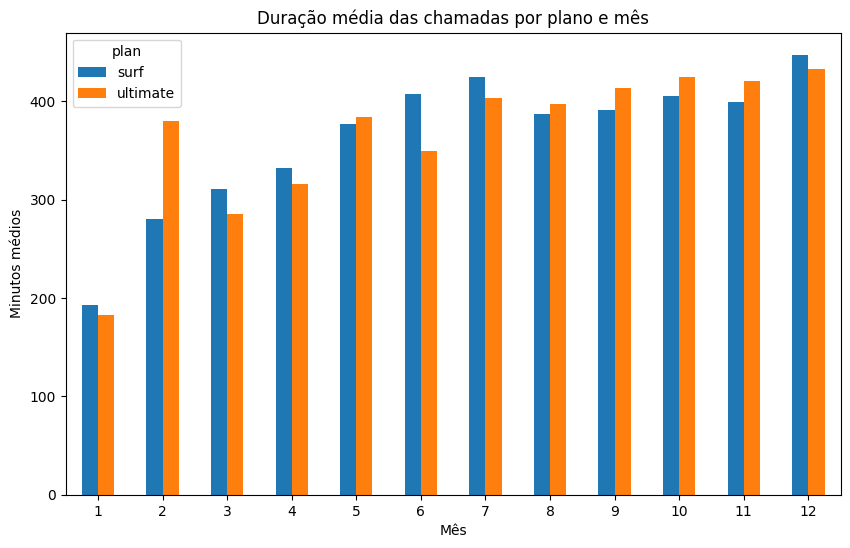

In [82]:
# Comparando a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.
import matplotlib.pyplot as plt 
avg_duration = (
    merged_df.groupby(['plan', 'month'])['total_per_month_minutes'].mean().reset_index()
)

pivot_duration = avg_duration.pivot(
    index='month',
    columns='plan',
    values='total_per_month_minutes'
)

pivot_duration.plot(kind='bar', figsize=(10,6), rot=0)
plt.title('Duração média das chamadas por plano e mês')
plt.xlabel('Mês')
plt.ylabel('Minutos médios')

plt.show()


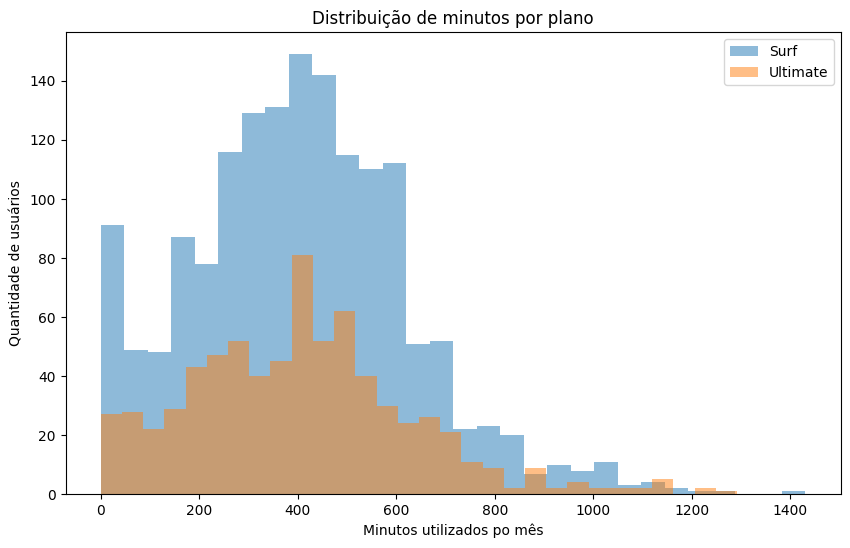

In [83]:
# Comparando o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.
surf_minutes = merged_df[merged_df['plan'] == 'surf']['total_per_month_minutes']
ultimate_minutes = merged_df[merged_df['plan'] == 'ultimate']['total_per_month_minutes']

plt.figure(figsize=(10,6))

plt.hist(surf_minutes, alpha=0.5, label='Surf', bins=30)
plt.hist(ultimate_minutes, alpha = 0.5, label='Ultimate', bins=30)
plt.title('Distribuição de minutos por plano')
plt.xlabel('Minutos utilizados po mês')
plt.ylabel('Quantidade de usuários')
plt.legend()

plt.show()



In [84]:
#  Média e a variância da duração mensal das chamadas
stats_duration = merged_df.groupby('plan')['total_per_month_minutes'].agg(['mean', 'var'])



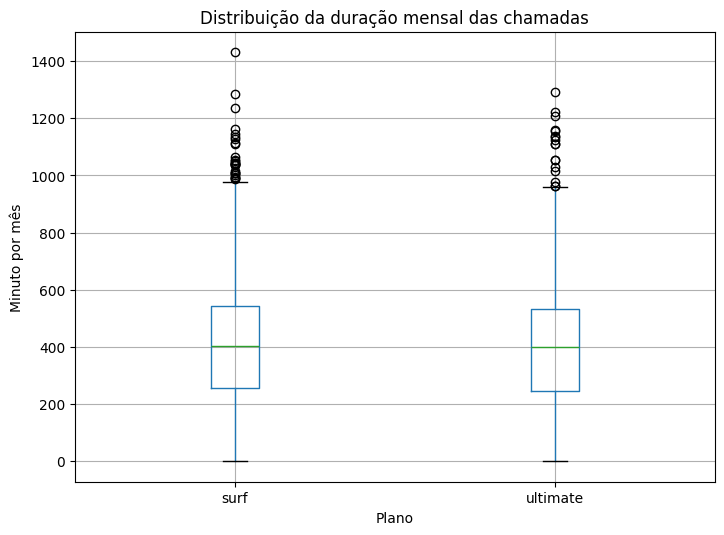

In [85]:
# Diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
merged_df.boxplot(column='total_per_month_minutes', by='plan', figsize=(8, 6))
plt.title('Distribuição da duração mensal das chamadas')
plt.suptitle('')
plt.xlabel('Plano')
plt.ylabel('Minuto por mês')

plt.show()


Sim, conforme o plano, o comportamento se difere bastante.

### Mensagens

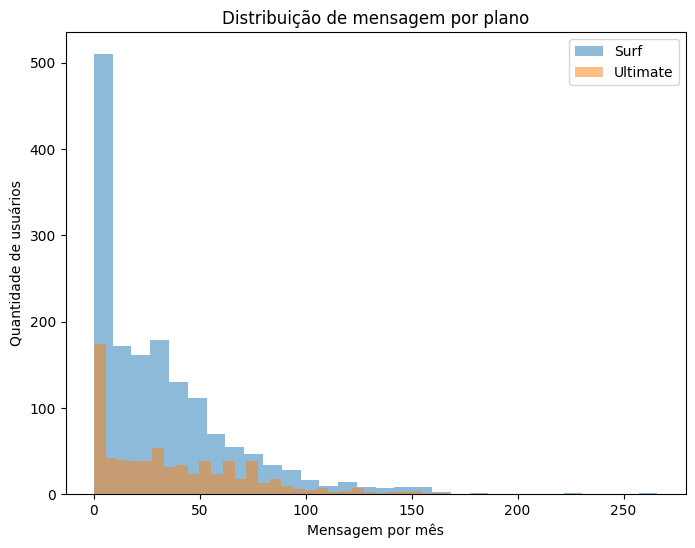

In [86]:
# Comparando o número de mensagens que os usuários de cada plano costumam enviar a cada mês
surf_messages = merged_df[merged_df['plan'] == 'surf']['messages_count']
ultimate_messages = merged_df[merged_df['plan'] == 'ultimate']['messages_count']

plt.figure(figsize=(8, 6))
plt.hist(surf_messages, bins = 30, label = 'Surf', alpha = 0.5)
plt.hist(ultimate_messages, bins = 30, label = 'Ultimate', alpha = 0.5)

plt.title('Distribuição de mensagem por plano')
plt.xlabel('Mensagem por mês')
plt.ylabel('Quantidade de usuários')
plt.legend()

plt.show()



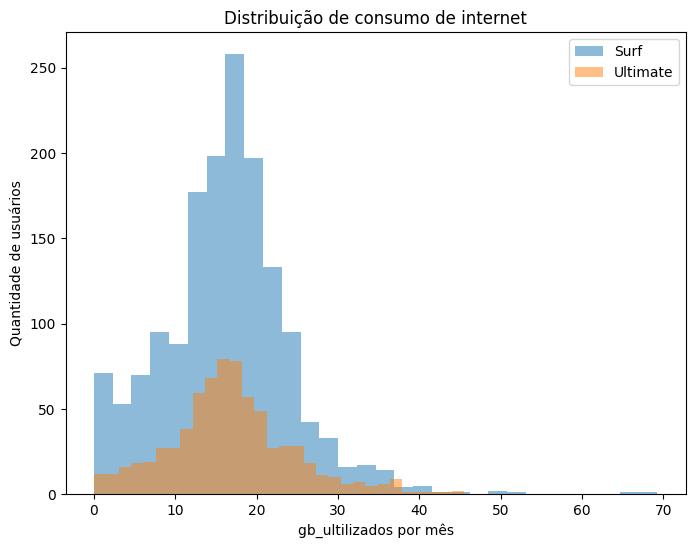

In [87]:
# Comparando a quantidade de tráfego de internet consumido pelos usuários por plano
surf_gb = merged_df[merged_df['plan'] == 'surf']['gb_used']
ultimate_gb = merged_df[merged_df['plan'] == 'ultimate']['gb_used']

plt.figure(figsize=(8, 6))
plt.hist(surf_gb, bins = 30, label = 'Surf', alpha = 0.5)
plt.hist(ultimate_gb, bins = 30, label = 'Ultimate', alpha = 0.5)

plt.title('Distribuição de consumo de internet')
plt.xlabel('gb_ultilizados por mês')
plt.ylabel('Quantidade de usuários')
plt.legend()

plt.show()




Sim, o comportamento se difere bastante conforme o plano.

### Internet

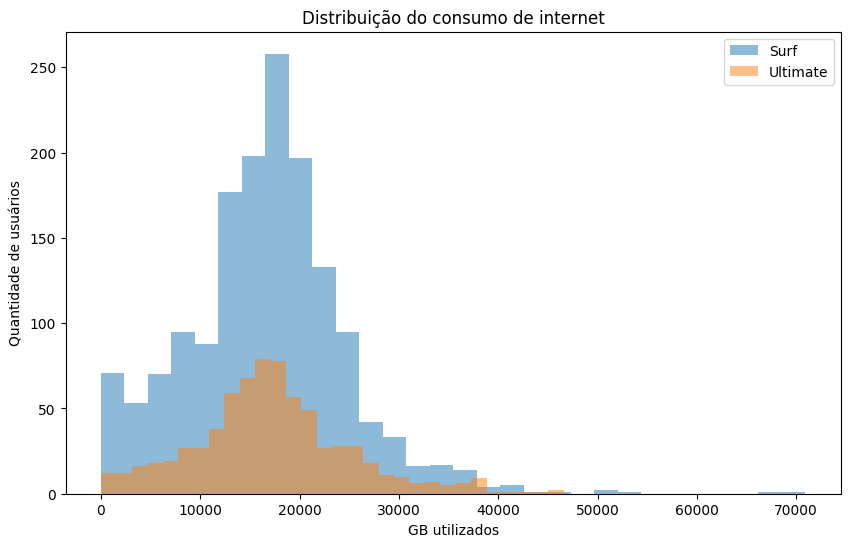

In [88]:
surf_gb = merged_df[merged_df['plan'] == 'surf']['count_internet']

ultimate_gb = merged_df[merged_df['plan'] == 'ultimate']['count_internet']

plt.figure(figsize=(10,6))

plt.hist(surf_gb, bins=30, alpha=0.5, label='Surf')

plt.hist(ultimate_gb, bins=30, alpha=0.5, label='Ultimate')

plt.title('Distribuição do consumo de internet')
plt.xlabel('GB utilizados')
plt.ylabel('Quantidade de usuários')

plt.legend()

plt.show()

Sim, ao analisar o histograma, foi possivel ver um grande diferença entre os dois planos.

## Receita

In [89]:
revenue_stats = merged_df.groupby('plan')['monthy_revenue'].agg(['mean', 'median', 'var', 'std', 'min', 'max'])

In [90]:
print(revenue_stats)

               mean   median          var        std   min         max
plan                                                                  
surf      57.293784  36.6818  2887.544971  53.735882  20.0  581.328509
ultimate  72.116080  70.0000   115.968081  10.768848  70.0  178.522764


O plano surf apresentou maior receita média e maior variabilidade, indicando que os usuários costumam gerar mais cobranças extras. Já o plano ultimate apresentou receitas menores e mais estáveis, sugerindo que os usuários excedem menos os limites do plano.

## Teste hipóteses estatísticas

Testando a hipótese de que a receita média dos usuários dos planos Ultimate e Surf são diferentes.

In [91]:
# Teste as hipóteses
# Receitas por plano
from scipy import stats as st
surf_revenue = merged_df[merged_df['plan'] == 'surf']['monthy_revenue']

ultimate_revenue = merged_df[merged_df['plan'] == 'ultimate']['monthy_revenue']

alpha = 0.05

results = st.ttest_ind(surf_revenue, ultimate_revenue, equal_var= False)

print('valor p', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')



valor p 4.881852673479728e-25
Rejeitamos a hipótese nula


Testando a hipótese de que a receita média dos usuários da área de NY-NJ difere dos usuários das demais regiões.

In [92]:

ny_nj_revenue = merged_df[merged_df['city'] == 'New York-Newark-Jersey City, NY-NJ-PA MSA']['monthy_revenue']

other_revenue = merged_df[merged_df['city'] != 'New York-Newark-Jersey City, NY-NJ-PA MSA']['monthy_revenue']

alpha = 0.05

results = st.ttest_ind(ny_nj_revenue, other_revenue)

print('valor p ', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')

valor p  0.026101704425405856
Rejeitamos a hipótese nula


Ao analisar os datasets eles nos mostraram que os usuários dos planos surf e ultimate possuem comportamentos diferentes de consumo e receita. Usuários do ultimate tendem a consumir mais internet, enquanto os do surf geram mais cobranças excedentes, aumentando a variabilidade da receita.
Foram utilizados gráficos, medidas estatísticas e testes de hipótese para comparar os planos e as regiões. Os resultados indicaram diferenças no comportamento dos usuários e no padrão de receita entre os grupos analisados.